In [1]:
# import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import  Path
import glob
from statsmodels.graphics.tsaplots import plot_acf
import holidays

pd.set_option("display.max_columns", None)
plt.style.use('dark_background')
plt.rcParams['axes.edgecolor'] = '#444444'
plt.rcParams['grid.color'] = '#333333'
plt.rcParams['grid.alpha'] = 0.8



In [2]:
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "processed"

In [3]:
demand_path = DATA_DIR / "gb_demand_2009_2025.parquet"
weather_path = DATA_DIR / "historical_weather_all.parquet"

df_demand = pd.read_parquet(demand_path)
df_weather = pd.read_parquet(weather_path)

In [4]:
#check shape and info of the dataset
print("Shape of demand dataset:", df_demand.shape)
print("Shape of weather dataset:", df_weather.shape)

Shape of demand dataset: (298032, 17)
Shape of weather dataset: (298031, 7)


In [5]:
#check info of dataset
df_demand.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 298032 entries, 0 to 298031
Data columns (total 17 columns):
 #   Column                     Non-Null Count   Dtype 
---  ------                     --------------   ----- 
 0   SETTLEMENT_DATE            298032 non-null  object
 1   SETTLEMENT_PERIOD          298032 non-null  int64 
 2   ND                         298032 non-null  int64 
 3   TSD                        298032 non-null  int64 
 4   ENGLAND_WALES_DEMAND       298032 non-null  int64 
 5   EMBEDDED_WIND_GENERATION   298032 non-null  int64 
 6   EMBEDDED_WIND_CAPACITY     298032 non-null  int64 
 7   EMBEDDED_SOLAR_GENERATION  298032 non-null  int64 
 8   EMBEDDED_SOLAR_CAPACITY    298032 non-null  int64 
 9   NON_BM_STOR                298032 non-null  int64 
 10  PUMP_STORAGE_PUMPING       298032 non-null  int64 
 11  IFA_FLOW                   298032 non-null  int64 
 12  IFA2_FLOW                  298032 non-null  int64 
 13  BRITNED_FLOW               298032 non-null  

In [6]:
df_weather.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 298031 entries, 0 to 298030
Data columns (total 7 columns):
 #   Column                Non-Null Count   Dtype              
---  ------                --------------   -----              
 0   time                  298031 non-null  datetime64[ns, UTC]
 1   temperature_2m        298031 non-null  float64            
 2   relative_humidity_2m  298031 non-null  float64            
 3   precipitation         298031 non-null  float64            
 4   cloud_cover           298031 non-null  float64            
 5   wind_speed_10m        298031 non-null  float64            
 6   shortwave_radiation   298031 non-null  float64            
dtypes: datetime64[ns, UTC](1), float64(6)
memory usage: 15.9 MB


In [7]:
df_demand.head(5)

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,NON_BM_STOR,PUMP_STORAGE_PUMPING,IFA_FLOW,IFA2_FLOW,BRITNED_FLOW,MOYLE_FLOW,EAST_WEST_FLOW,NEMO_FLOW
0,01-JAN-2022,1,21940,23275,20513,2713,6527,0,14008,0,450,-181,-4,586,320,384,-100
1,01-JAN-2022,2,22427,23489,21021,2755,6527,0,14008,0,173,-181,-4,583,320,403,-104
2,01-JAN-2022,3,21896,23672,20619,2930,6527,0,14008,0,799,-164,-4,567,320,440,-4
3,01-JAN-2022,4,20693,23272,19615,3090,6527,0,14008,0,1516,-170,-4,444,320,387,-6
4,01-JAN-2022,5,19481,23958,18545,3161,6527,0,14008,0,1490,-753,-4,-383,320,476,-561


In [8]:
#df_demand = df_demand[['SETTLEMENT_DATE','SETTLEMENT_PERIOD','ND','EMBEDDED_WIND_GENERATION','EMBEDDED_SOLAR_GENERATION','ENGLAND_WALES_DEMAND']].copy()

#check first few rows of dataset
df_demand.head(5)

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,NON_BM_STOR,PUMP_STORAGE_PUMPING,IFA_FLOW,IFA2_FLOW,BRITNED_FLOW,MOYLE_FLOW,EAST_WEST_FLOW,NEMO_FLOW
0,01-JAN-2022,1,21940,23275,20513,2713,6527,0,14008,0,450,-181,-4,586,320,384,-100
1,01-JAN-2022,2,22427,23489,21021,2755,6527,0,14008,0,173,-181,-4,583,320,403,-104
2,01-JAN-2022,3,21896,23672,20619,2930,6527,0,14008,0,799,-164,-4,567,320,440,-4
3,01-JAN-2022,4,20693,23272,19615,3090,6527,0,14008,0,1516,-170,-4,444,320,387,-6
4,01-JAN-2022,5,19481,23958,18545,3161,6527,0,14008,0,1490,-753,-4,-383,320,476,-561


In [9]:
# Create a full timestamp
#convert settlement_date to a datetime object
df_demand["SETTLEMENT_DATE"] = pd.to_datetime(df_demand["SETTLEMENT_DATE"],format="mixed", dayfirst=True)

# Interpret midnight as UK local time
settlement_midnight = df_demand["SETTLEMENT_DATE"].dt.tz_localize("Europe/London")

# Construct the local settlement timestamp
df_demand["datetime_local"] = (settlement_midnight+ pd.to_timedelta(
    (df_demand["SETTLEMENT_PERIOD"] - 1) * 30,unit="minutes"))

# Convert to UTC for the canonical timestamp
df_demand["datetime"] = df_demand["datetime_local"].dt.tz_convert("UTC")

df_demand = df_demand.sort_values("datetime").reset_index(drop=True)

In [10]:

#merge the demand and weather datasets on the datetime column
df_weather['datetime'] = pd.to_datetime(df_weather['time'])
df_weather = df_weather.sort_values("datetime").reset_index(drop=True)


In [11]:
df_weather['time'].head()

0   2009-01-01 00:00:00+00:00
1   2009-01-01 00:30:00+00:00
2   2009-01-01 01:00:00+00:00
3   2009-01-01 01:30:00+00:00
4   2009-01-01 02:00:00+00:00
Name: time, dtype: datetime64[ns, UTC]

In [12]:
df = pd.merge(df_demand,df_weather,on='datetime',how='left', validate ='one_to_one')

In [13]:
#check missing values in the merged dataset
df.isnull().sum()


SETTLEMENT_DATE              0
SETTLEMENT_PERIOD            0
ND                           0
TSD                          0
ENGLAND_WALES_DEMAND         0
EMBEDDED_WIND_GENERATION     0
EMBEDDED_WIND_CAPACITY       0
EMBEDDED_SOLAR_GENERATION    0
EMBEDDED_SOLAR_CAPACITY      0
NON_BM_STOR                  0
PUMP_STORAGE_PUMPING         0
IFA_FLOW                     0
IFA2_FLOW                    0
BRITNED_FLOW                 0
MOYLE_FLOW                   0
EAST_WEST_FLOW               0
NEMO_FLOW                    0
datetime_local               0
datetime                     0
time                         1
temperature_2m               1
relative_humidity_2m         1
precipitation                1
cloud_cover                  1
wind_speed_10m               1
shortwave_radiation          1
dtype: int64

In [14]:
#create time features
# Create time features from UK local time
df['year'] = df['datetime_local'].dt.year
df['month'] = df['datetime_local'].dt.month
df['day_of_week'] = df['datetime_local'].dt.dayofweek
df['hour'] = df['datetime_local'].dt.hour
df['minute'] = df['datetime_local'].dt.minute
df['day_of_year'] = df['datetime_local'].dt.dayofyear
df['quarter'] = df['datetime_local'].dt.quarter
df['is_weekend'] = (df['datetime_local'].dt.dayofweek >= 5).astype(int)

In [15]:
#add holidays columms
uk_holidays = holidays.UnitedKingdom(years = range(2009,2026))
holiday_dates = pd.to_datetime(list(uk_holidays.keys()))


holiday_dates = set(uk_holidays.keys())

df["is_holiday"] = df["datetime_local"].dt.date.isin(holiday_dates).astype(int)


In [16]:
df["is_holiday"].value_counts()

is_holiday
0    292176
1      5856
Name: count, dtype: int64

In [17]:
#set datetime as index
df = df.set_index('datetime')

In [18]:

#check missing values in the dataset
df[df.isna().any(axis=1)]

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,NON_BM_STOR,PUMP_STORAGE_PUMPING,IFA_FLOW,IFA2_FLOW,BRITNED_FLOW,MOYLE_FLOW,EAST_WEST_FLOW,NEMO_FLOW,datetime_local,time,temperature_2m,relative_humidity_2m,precipitation,cloud_cover,wind_speed_10m,shortwave_radiation,year,month,day_of_week,hour,minute,day_of_year,quarter,is_weekend,is_holiday
datetime,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-12-31 23:30:00+00:00,2025-12-31,48,24730,30085,23230,4171,6606,0,22126,0,459,-1319,-666,615,-428,-513,-442,2025-12-31 23:30:00+00:00,NaT,NaN,NaN,NaN,NaN,NaN,NaN,2025,12,2,23,30,365,4,0,0


In [19]:
df.dropna(inplace=True)

In [20]:
#check summary statistics of the dataset
df.describe().round(2)

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,NON_BM_STOR,PUMP_STORAGE_PUMPING,IFA_FLOW,IFA2_FLOW,BRITNED_FLOW,MOYLE_FLOW,EAST_WEST_FLOW,NEMO_FLOW,temperature_2m,relative_humidity_2m,precipitation,cloud_cover,wind_speed_10m,shortwave_radiation,year,month,day_of_week,hour,minute,day_of_year,quarter,is_weekend,is_holiday
count,298031,298031.00,298031.00,298031.00,298031.00,298031.00,298031.00,298031.00,298031.00,298031.00,298031.00,298031.00,298031.00,298031.00,298031.00,298031.00,298031.00,298031.00,298031.00,298031.00,298031.00,298031.00,298031.00,298031.0,298031.00,298031.0,298031.00,298031.0,298031.00,298031.00,298031.00,298031.00
mean,2017-07-02 00:20:06.575154944,24.50,30883.89,32384.89,28127.12,1349.51,4583.64,966.30,9563.92,6.24,296.70,940.35,90.25,475.29,-133.68,-60.02,179.52,10.54,81.59,0.10,70.95,4.22,114.17,2017.0,6.52,3.0,11.50,15.0,183.14,2.51,0.29,0.02
min,2009-01-01 00:00:00,1.00,12803.00,0.00,0.00,0.00,1403.00,0.00,0.00,-24.00,0.00,-2071.00,-1030.00,-1215.00,-505.00,-585.00,-1024.00,-6.70,28.44,0.00,0.00,0.67,0.00,2009.0,1.00,0.0,0.00,0.0,1.00,1.00,0.00,0.00
25%,2013-04-02 00:00:00,12.50,24593.00,26353.00,22409.00,574.00,2121.00,0.00,2597.00,0.00,8.00,329.00,0.00,0.00,-327.00,-226.00,0.00,6.62,75.67,0.00,54.33,2.82,0.00,2013.0,4.00,1.0,5.50,0.0,92.00,2.00,0.00,0.00
50%,2017-07-02 00:00:00,24.00,30130.00,31496.00,27431.00,1054.00,5143.00,0.00,12372.00,0.00,11.00,1203.00,0.00,700.00,-157.00,0.00,0.00,10.48,84.56,0.01,76.67,3.90,5.89,2017.0,7.00,3.0,11.00,0.0,183.00,3.00,0.00,0.00
75%,2021-10-01 00:00:00,36.00,36598.00,37828.00,33337.00,1823.00,6527.00,982.00,13815.00,0.00,327.00,1878.00,0.00,994.00,14.00,0.00,452.00,14.44,89.89,0.11,92.44,5.31,183.22,2021.0,10.00,5.0,17.00,30.0,274.00,4.00,1.00,0.00
max,2025-12-31 00:00:00,50.00,59095.00,60147.00,53325.00,5962.00,6622.00,14046.00,22126.00,893.00,2019.00,2066.00,1058.00,1143.00,499.00,504.00,1063.00,33.09,99.89,2.74,100.00,13.78,873.67,2025.0,12.00,6.0,23.00,30.0,366.00,4.00,1.00,1.00
std,NaN,13.85,7824.22,7677.66,7079.61,1055.50,1965.83,1896.54,6505.55,37.93,518.71,1052.13,390.89,563.75,231.93,263.94,442.14,5.38,11.06,0.19,24.94,1.81,171.34,4.9,3.45,2.0,6.92,15.0,105.44,1.12,0.45,0.14


In [21]:
#check summary statistics for the demand column for each year
df[['ND','year']].groupby(by ='year')['ND'].agg(Mean ='mean',STD ='std', Max ='max',Min ='min').round()



,Mean,STD,Max,Min
year,,,,
2009,35919.0,7760.0,58594,19557
2010,36535.0,8144.0,59095,19424
2011,35150.0,7605.0,55113,19347
2012,35181.0,7442.0,55765,19219
2013,34885.0,7603.0,55572,18555
2014,33169.0,7143.0,51208,18074
2015,32223.0,7104.0,52516,17909
2016,31375.0,7022.0,51102,16396
2017,30373.0,7011.0,49883,16574


In [22]:
#check for duplicates
duplicate_rows  = df.index.duplicated().sum()
print(duplicate_rows)

0


In [23]:
#check for duplicates
duplicate_rows  = df[df.duplicated()]
print(duplicate_rows)

Empty DataFrame
Columns: [SETTLEMENT_DATE, SETTLEMENT_PERIOD, ND, TSD, ENGLAND_WALES_DEMAND, EMBEDDED_WIND_GENERATION, EMBEDDED_WIND_CAPACITY, EMBEDDED_SOLAR_GENERATION, EMBEDDED_SOLAR_CAPACITY, NON_BM_STOR, PUMP_STORAGE_PUMPING, IFA_FLOW, IFA2_FLOW, BRITNED_FLOW, MOYLE_FLOW, EAST_WEST_FLOW, NEMO_FLOW, datetime_local, time, temperature_2m, relative_humidity_2m, precipitation, cloud_cover, wind_speed_10m, shortwave_radiation, year, month, day_of_week, hour, minute, day_of_year, quarter, is_weekend, is_holiday]
Index: []


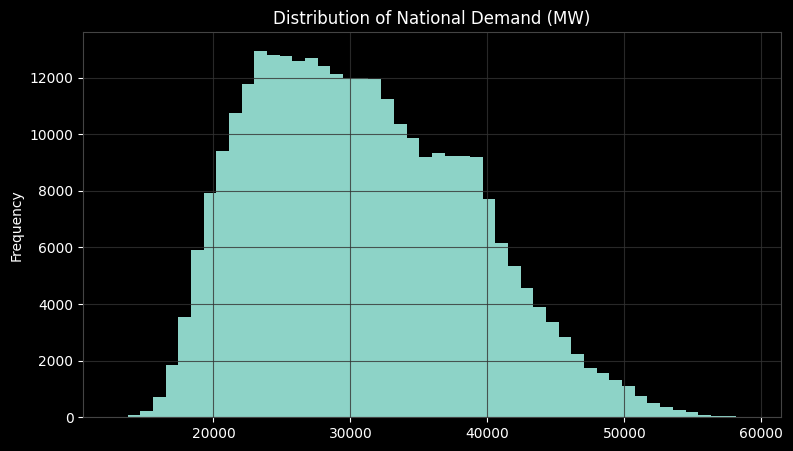

In [24]:

#check demand distribution 
plt.figure(figsize = (9,5))
df['ND'].hist(bins = 50)
plt.title("Distribution of National Demand (MW)")
plt.ylabel("Frequency")
plt.show()


<Figure size 1500x1000 with 0 Axes>

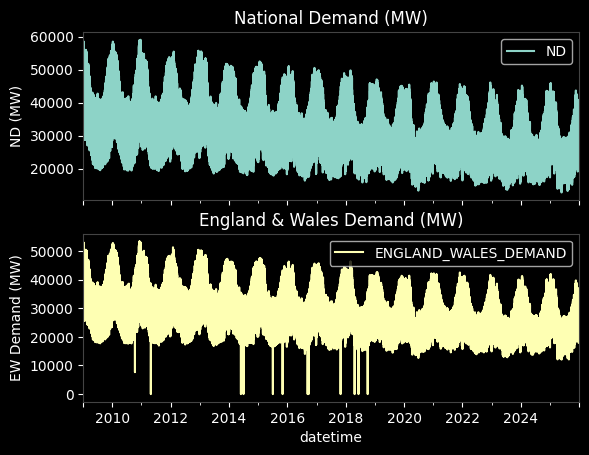

In [25]:
plt.figure(figsize = (15,10))
ax = df[['ND','ENGLAND_WALES_DEMAND']].plot(subplots=True)
ax[0].set_title("National Demand (MW)")
ax[0].set_ylabel("ND (MW)")
ax[1].set_title("England & Wales Demand (MW)")
ax[1].set_ylabel("EW Demand (MW)")
plt.show()

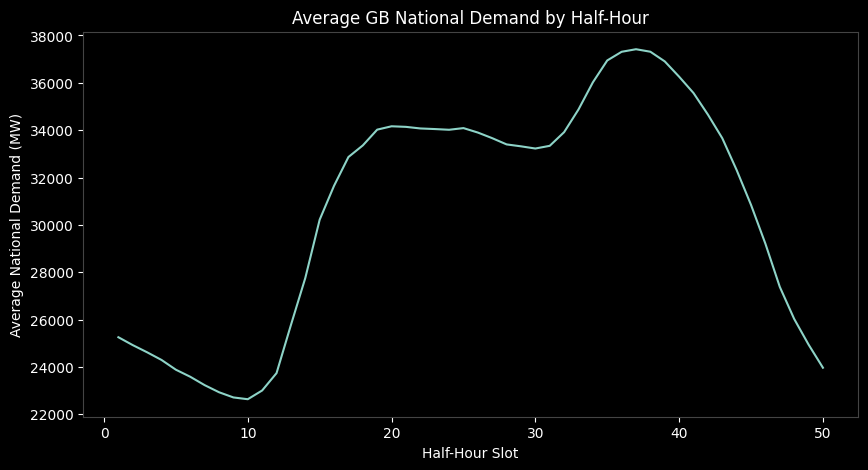

In [26]:
df["half_hour_slot"] = df["hour"] * 2 + (df["minute"] // 30)


half_hourly_demand = df.groupby("SETTLEMENT_PERIOD")["ND"].mean()


#half_hourly_demand = df.groupby("half_hour_slot")["ND"].mean()

half_hourly_demand.plot(figsize=(10, 5))
plt.title("Average GB National Demand by Half-Hour")
plt.xlabel("Half-Hour Slot")
plt.ylabel("Average National Demand (MW)")
plt.show()

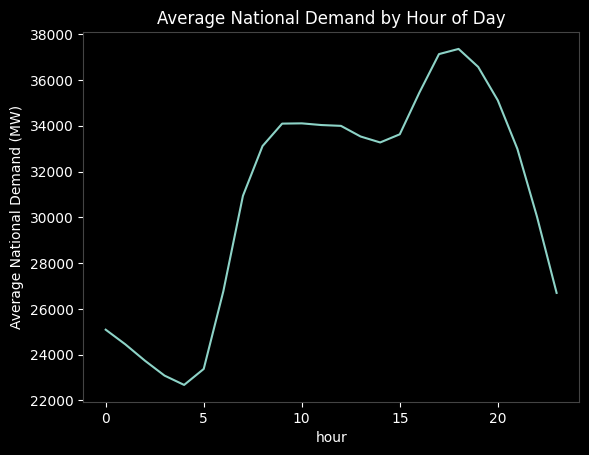

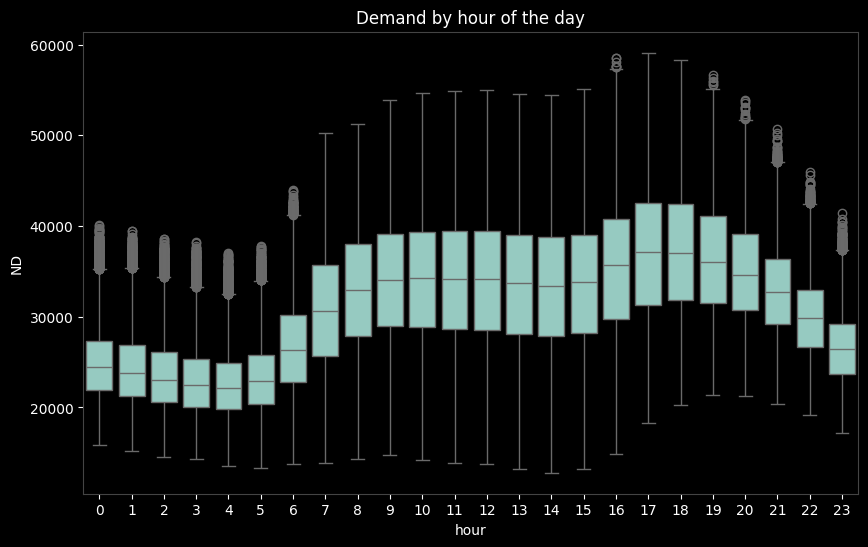

In [27]:
#daily pattern 
hourly_demand = df.groupby('hour')['ND'].mean()

hourly_demand.plot()
plt.title("Average National Demand by Hour of Day")
plt.ylabel("Average National Demand (MW)")
plt.show()

#Demand was quite low during the periods between 3 am to 5 am
#Demand started rising after 5 am and plateaued at 10 am before rising and peaking at around 6pm
# demand kept falling from evening to morning 


plt.figure(figsize = (10,6))
sns.boxplot(data = df,x = 'hour', y='ND',)
plt.title('Demand by hour of the day')
plt.show()


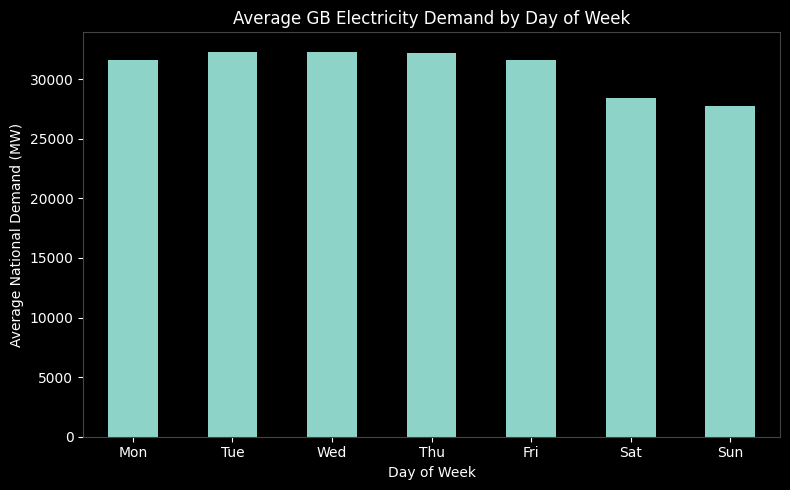

In [28]:
#weekly pattern
daily_avg = df.groupby('day_of_week')['ND'].mean()

#plotting the average demand for each day of the week
days = ["Mon", "Tue", "Wed","Thu", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(8, 5))
daily_avg.plot(kind="bar", ax=ax)
ax.set_xticks(range(len(days)))
ax.set_xticklabels(days, rotation=0)
ax.set_xlabel("Day of Week")
ax.set_ylabel("Average National Demand (MW)")
ax.set_title("Average GB Electricity Demand by Day of Week")

plt.tight_layout()
plt.show()


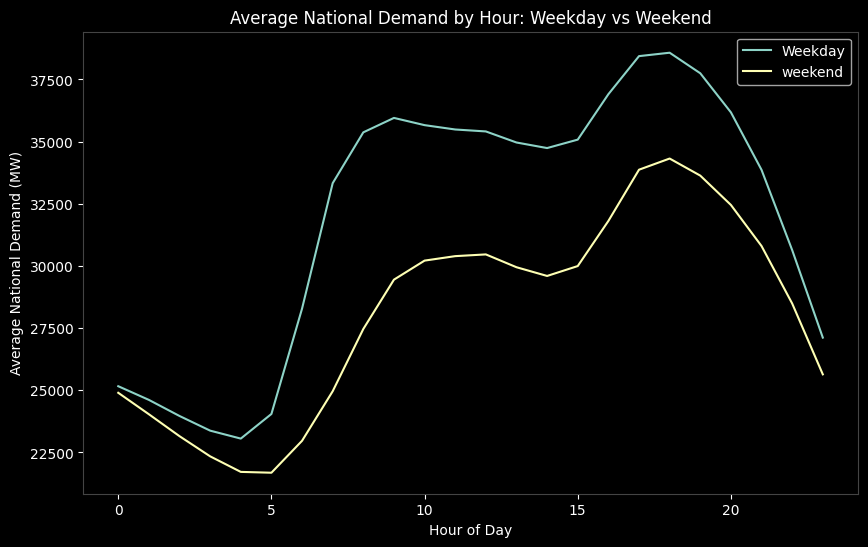

In [29]:

#check hourly average demand for weekdays and weekends
weekday_hourly = df[df["is_weekend"] == 0].groupby("hour")["ND"].mean()
weekend_hourly = df[df["is_weekend"] == 1].groupby("hour")["ND"].mean()


fig, ax = plt.subplots(figsize = (10,6))
weekday_hourly.plot(ax=ax, label= 'Weekday')
weekend_hourly.plot(ax=ax,label= 'weekend')

ax.set_title("Average National Demand by Hour: Weekday vs Weekend")
ax.set_ylabel("Average National Demand (MW)")
ax.set_xlabel("Hour of Day")
plt.legend()
plt.show()

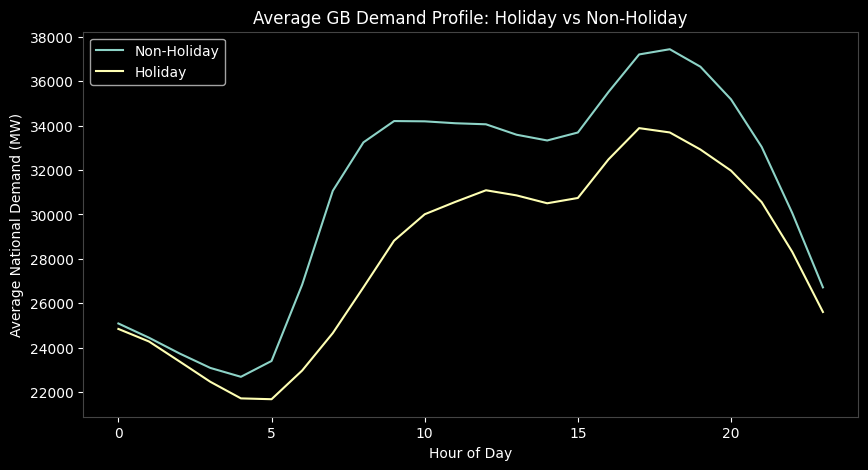

In [30]:
holiday_hourly = (
    df.groupby(["is_holiday", "hour"])["ND"]
    .mean()
    .unstack(level=0)
)

holiday_hourly.columns = [
    "Non-Holiday",
    "Holiday"
]

holiday_hourly.plot(figsize=(10, 5))

plt.title("Average GB Demand Profile: Holiday vs Non-Holiday")
plt.xlabel("Hour of Day")
plt.ylabel("Average National Demand (MW)")
plt.show()

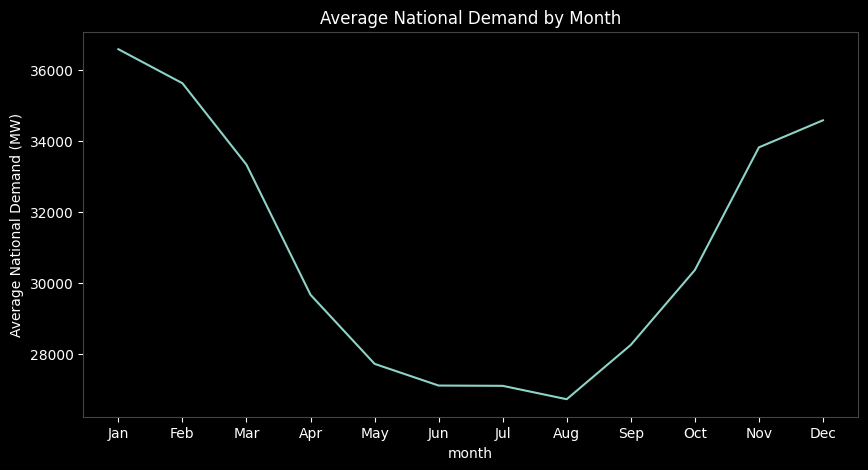

In [31]:
#monthly pattern
monthly_avg = df.groupby("month")["ND"].mean()
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun","Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize =(10,5))
monthly_avg.plot(ax=ax)
ax.set_xticks(monthly_avg.index)
ax.set_xticklabels(months, rotation = 0)
ax.set_title("Average National Demand by Month")
ax.set_ylabel("Average National Demand (MW)")
plt.show()

NameError: name 'year_month_avg' is not defined

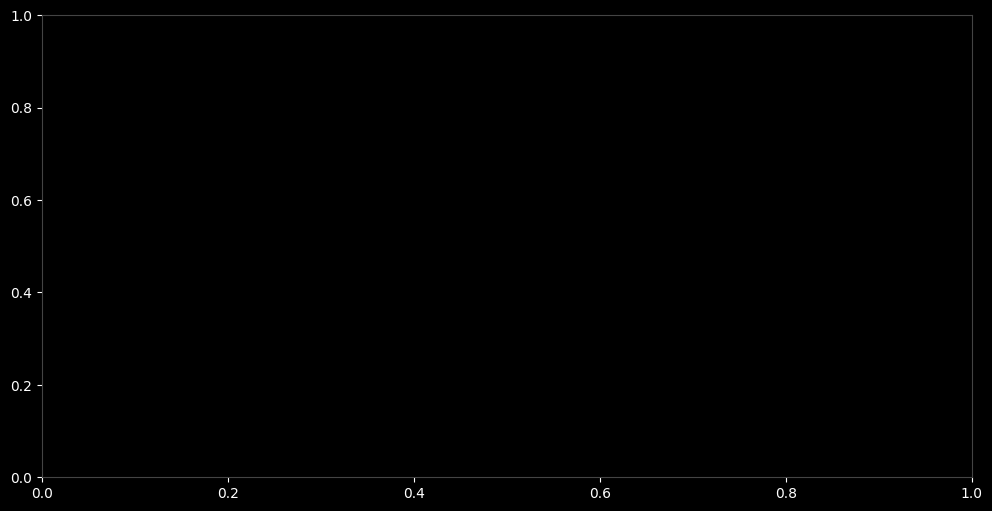

In [32]:
#Yearly-monthly pattern
# Year-month pattern
fig, ax = plt.subplots(figsize=(12, 6))

year_month_avg.plot(ax=ax)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(months, rotation=0)

# Vertical lines at May and August
ax.axvline(x=5, linestyle="--", alpha=0.7)
ax.axvline(x=8, linestyle="--", alpha=0.7)

ax.set_title("Monthly GB National Demand by Year")
ax.set_xlabel("Month")
ax.set_ylabel("Average National Demand (MW)")
ax.legend(title="Year", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

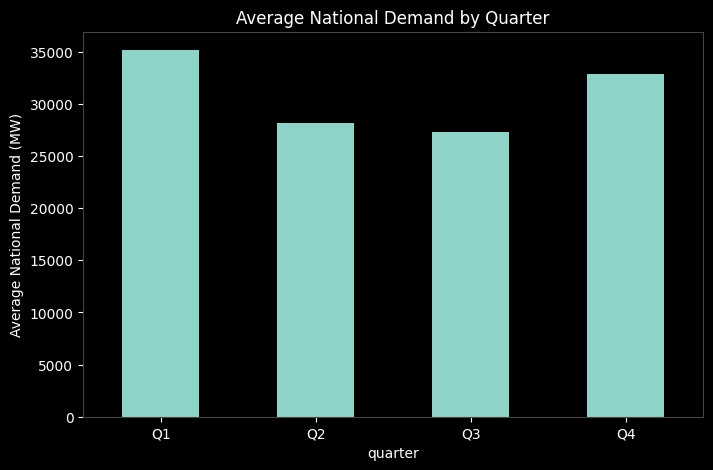

In [ ]:

#check quarterly
quarterly_avg = df.groupby('quarter')['ND'].mean()
fig, ax = plt.subplots(figsize=(8, 5))
quarterly_avg.plot(kind = 'bar', ax=ax)
ax.set_xticks(range(4))
ax.set_xticklabels(["Q1", "Q2", "Q3", "Q4"], rotation=0)
ax.set_title("Average National Demand by Quarter")
ax.set_ylabel("Average National Demand (MW)")
plt.show()

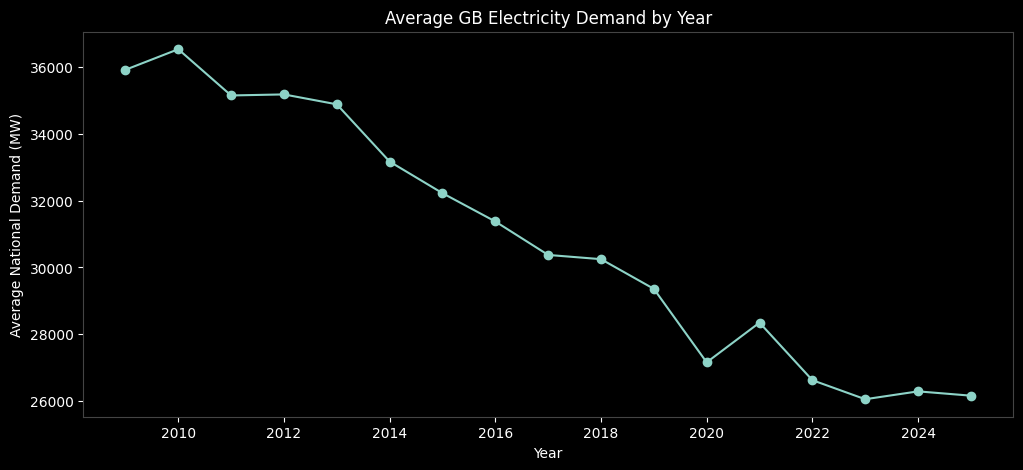

In [ ]:
#yearly demand 
yearly_avg = df.groupby("year")["ND"].mean()


fig, ax = plt.subplots(figsize=(12,5))

yearly_avg.plot(ax=ax,marker="o")

ax.set_title("Average GB Electricity Demand by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Average National Demand (MW)")
plt.show()

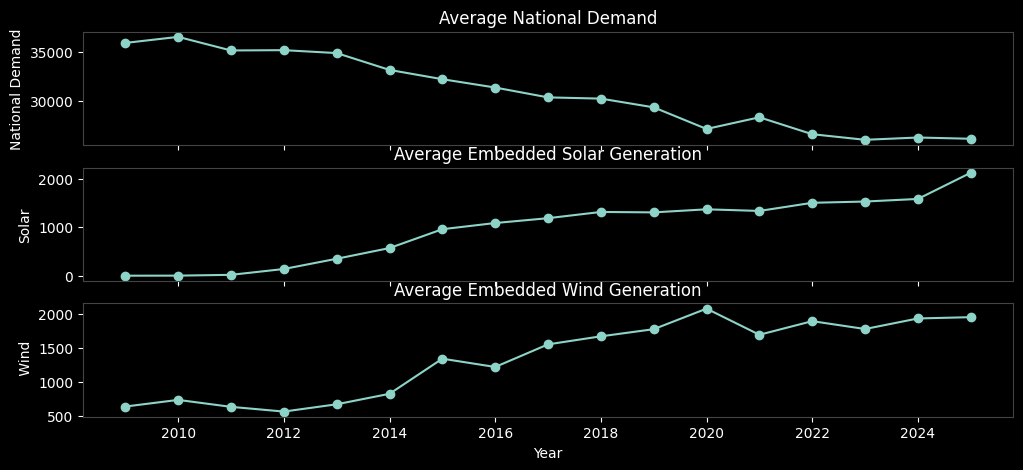

In [ ]:
yearly_avg_wind = df.groupby("year")["EMBEDDED_WIND_GENERATION"].mean()
yearly_avg_solar = df.groupby('year')['EMBEDDED_SOLAR_GENERATION'].mean()


fig, ax = plt.subplots(figsize=(12,5),nrows=3, ncols= 1, sharex=True)
yearly_avg.plot(ax=ax[0],marker="o", label = 'ND')
ax[0].set_title('Average National Demand')
ax[0].set_ylabel('National Demand')
yearly_avg_solar.plot(ax=ax[1],marker="o",label ='Solar')
ax[1].set_ylabel('Solar')
ax[1].set_title('Average Embedded Solar Generation')
yearly_avg_wind.plot(ax=ax[2],marker="o",label ='Wind')
ax[2].set_ylabel(' Wind')
ax[2].set_title('Average Embedded Wind Generation')
ax[2].set_xlabel("Year")
plt.show()

In [ ]:


#Plot demand vs weather variables
def plot_demand_vs_weather(df, variable_list):
    length = len(variable_list)
    fig, axes = plt.subplots(figsize=(10,6*length), nrows=length, ncols=1)
    for ax,variable in zip(axes,variable_list):
        sns.scatterplot(data=df, x=variable, y="ND",ax=ax)
        ax.set_title(f"{variable} vs National Demand")
        ax.set_xlabel(variable)
        ax.set_ylabel("National Demand (MW)")


    plt.tight_layout()
    plt.show()

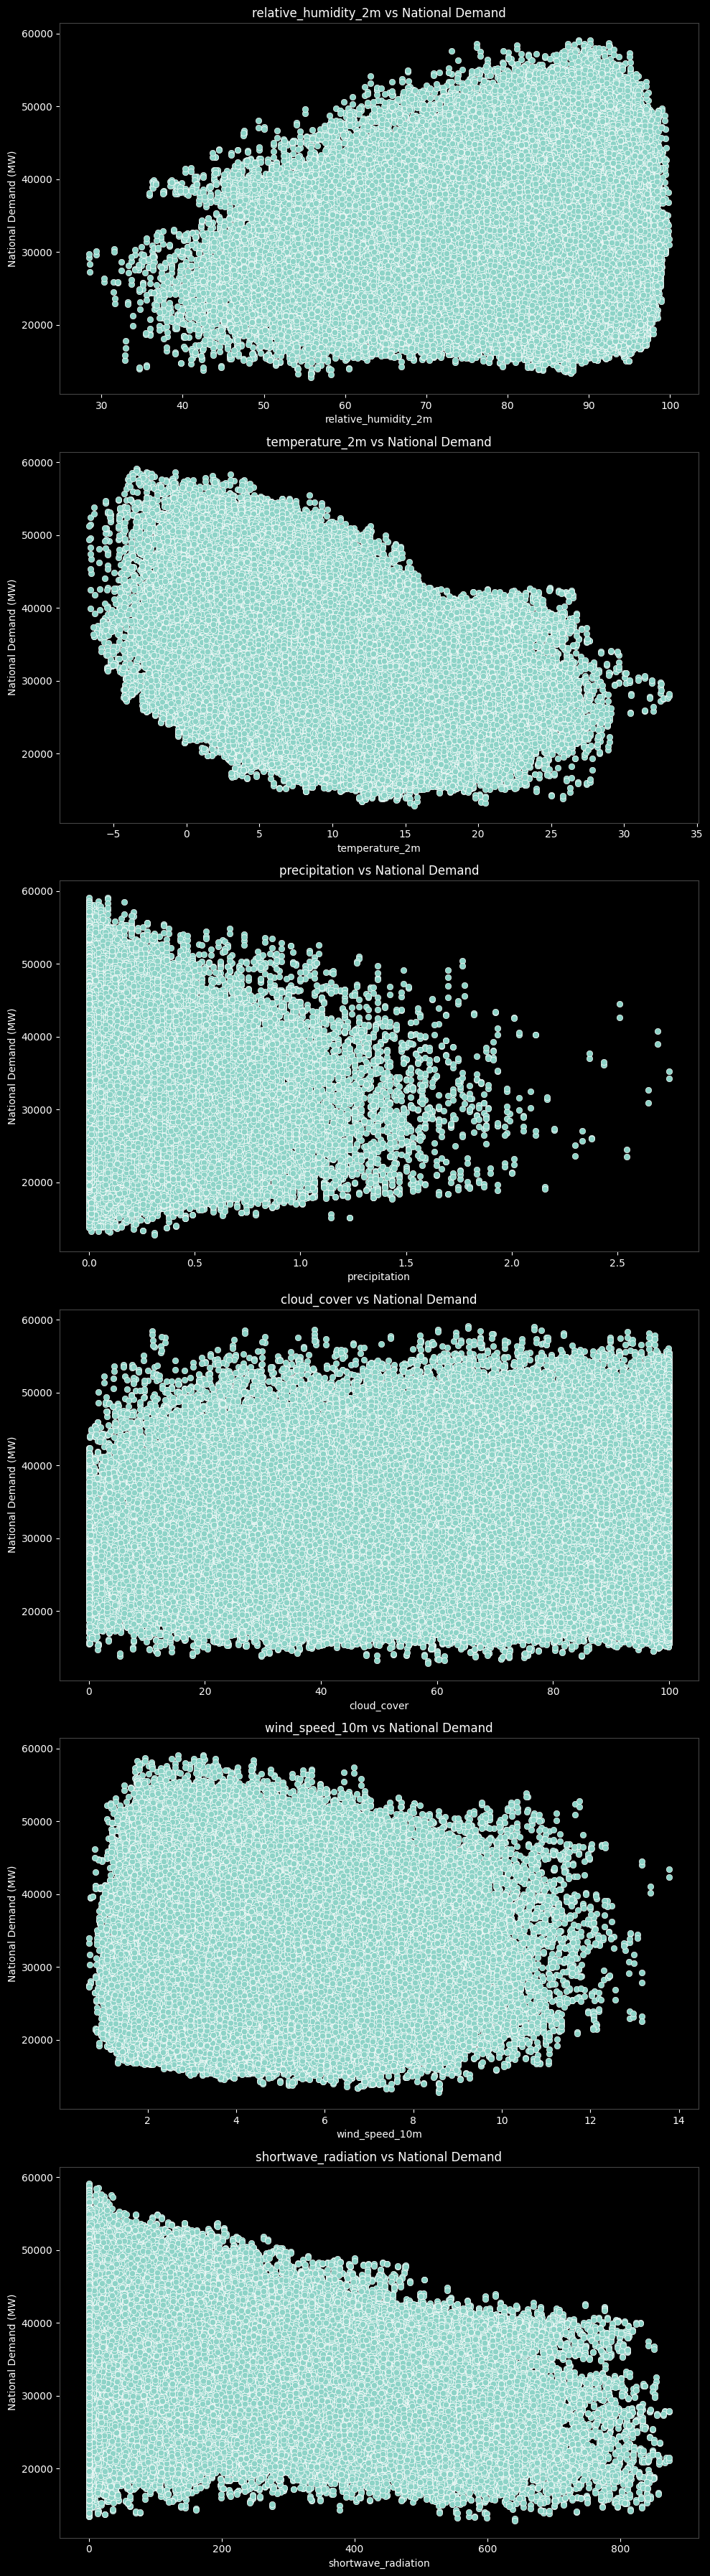

In [ ]:

variable_list =["relative_humidity_2m","temperature_2m","precipitation",
                "cloud_cover","wind_speed_10m","shortwave_radiation",]

df_sample = df.sample(n=min(30000,len(df)), random_state=42) 
plot_demand_vs_weather(df, variable_list)

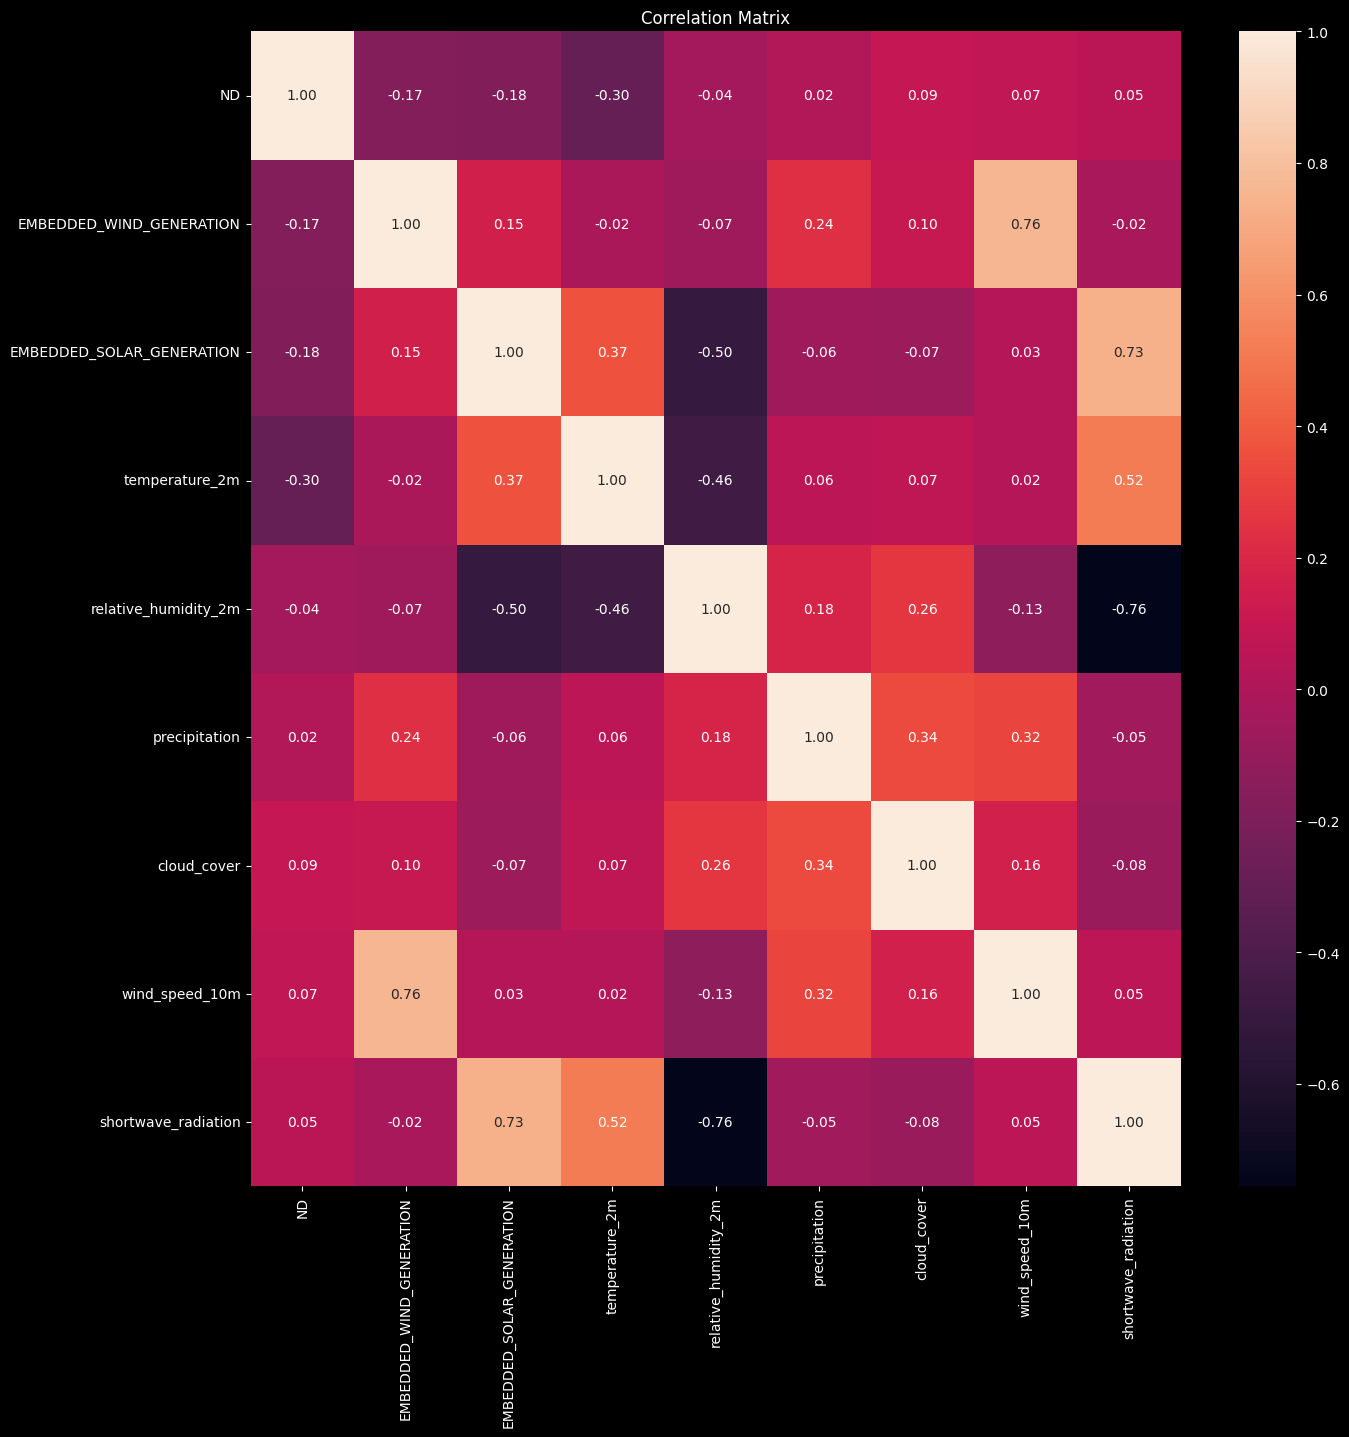

In [ ]:
# check correlation
col = ['ND', 'EMBEDDED_WIND_GENERATION', 'EMBEDDED_SOLAR_GENERATION',
     'temperature_2m', 'relative_humidity_2m', 'precipitation', 'cloud_cover',
     'wind_speed_10m', 'shortwave_radiation']

plt.figure(figsize=(15,15))
sns.heatmap(df[col].corr(),annot=True,fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

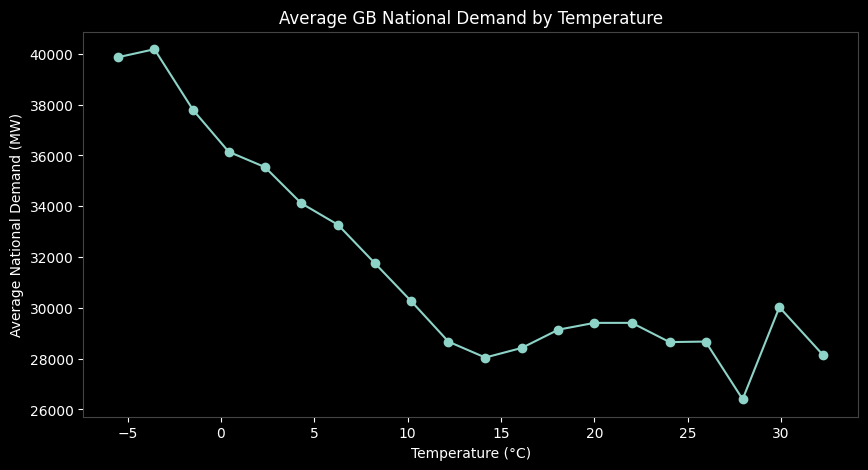

In [ ]:
#check relationship between temperature and demand
temp_bins = pd.cut(df["temperature_2m"],bins=20)

temp_demand = (df.groupby(temp_bins, observed=True)
               .agg(temperature=("temperature_2m", "mean"),demand=("ND", "mean")))

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(temp_demand["temperature"],temp_demand["demand"],marker="o")

ax.set_title("Average GB National Demand by Temperature")
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Average National Demand (MW)")

plt.show()

<Figure size 3000x2000 with 0 Axes>

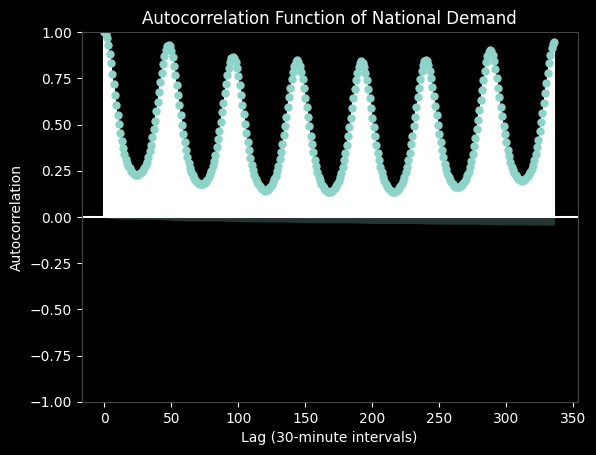

In [ ]:

#add lag features
plt.figure(figsize=(30, 20))
plot_acf(df["ND"],lags= 336)
plt.title("Autocorrelation Function of National Demand")
plt.xlabel("Lag (30-minute intervals)")
plt.ylabel("Autocorrelation")
plt.show()

In [ ]:
lags = [1, 2, 48, 96, 336]

for lag in lags:
    print(
        f"Lag {lag}:",
        round(df["ND"].autocorr(lag=lag), 3)
    )

Lag 1: 0.991
Lag 2: 0.966
Lag 48: 0.933
Lag 96: 0.868
Lag 336: 0.947


In [ ]:

#create lags of 24h and weekly
df['lag_24h'] = df['ND'].shift(48)
df["lag_48h"] = df["ND"].shift(96)
df['lag_168h'] = df['ND'].shift(336)

df.iloc[329:350].head(30)

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,NON_BM_STOR,PUMP_STORAGE_PUMPING,IFA_FLOW,IFA2_FLOW,BRITNED_FLOW,MOYLE_FLOW,EAST_WEST_FLOW,NEMO_FLOW,datetime_local,time,temperature_2m,relative_humidity_2m,precipitation,cloud_cover,wind_speed_10m,shortwave_radiation,year,month,day_of_week,hour,minute,day_of_year,quarter,is_weekend,is_holiday,half_hour_slot,lag_24h,lag_168h
datetime,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2009-01-07 20:30:00+00:00,2009-01-07,42,50014,50617,45242,152,1403,0,0,0,3,361,0,0,41,0,0,2009-01-07 20:30:00+00:00,2009-01-07 20:30:00+00:00,3.055556,94.111111,0.0,81.555556,1.856667,0.0,2009,1,2,20,30,7,1,0,0,41,51282.0,NaN
2009-01-07 21:00:00+00:00,2009-01-07,43,48340,49044,43683,152,1403,0,0,0,3,-23,0,0,-78,0,0,2009-01-07 21:00:00+00:00,2009-01-07 21:00:00+00:00,3.144444,94.333333,0.0,84.333333,1.766667,0.0,2009,1,2,21,0,7,1,0,0,42,49370.0,NaN
2009-01-07 21:30:00+00:00,2009-01-07,44,46236,46960,41805,112,1403,0,0,0,4,-19,0,0,-101,0,0,2009-01-07 21:30:00+00:00,2009-01-07 21:30:00+00:00,3.144444,94.333333,0.0,84.333333,1.766667,0.0,2009,1,2,21,30,7,1,0,0,43,47010.0,NaN
2009-01-07 22:00:00+00:00,2009-01-07,45,43706,44911,39432,112,1403,0,0,0,11,-483,0,0,-111,0,0,2009-01-07 22:00:00+00:00,2009-01-07 22:00:00+00:00,2.777778,94.666667,0.0,83.444444,1.752222,0.0,2009,1,2,22,0,7,1,0,0,44,44653.0,NaN
2009-01-07 22:30:00+00:00,2009-01-07,46,41520,42808,37274,110,1403,0,0,0,107,-581,0,0,24,0,0,2009-01-07 22:30:00+00:00,2009-01-07 22:30:00+00:00,2.777778,94.666667,0.0,83.444444,1.752222,0.0,2009,1,2,22,30,7,1,0,0,45,42281.0,NaN
2009-01-07 23:00:00+00:00,2009-01-07,47,39085,41667,35074,110,1403,0,0,0,1109,-873,0,0,16,0,0,2009-01-07 23:00:00+00:00,2009-01-07 23:00:00+00:00,2.766667,94.888889,0.0,88.555556,1.990000,0.0,2009,1,2,23,0,7,1,0,0,46,39576.0,NaN
2009-01-07 23:30:00+00:00,2009-01-07,48,37606,41034,33855,114,1403,0,0,0,1436,-1276,0,0,-116,0,0,2009-01-07 23:30:00+00:00,2009-01-07 23:30:00+00:00,2.766667,94.888889,0.0,88.555556,1.990000,0.0,2009,1,2,23,30,7,1,0,0,47,38394.0,NaN
2009-01-08 00:00:00+00:00,2009-01-08,1,38055,41333,34394,114,1403,0,0,0,1267,-1318,0,0,-93,0,0,2009-01-08 00:00:00+00:00,2009-01-08 00:00:00+00:00,2.800000,95.111111,0.0,93.222222,2.141111,0.0,2009,1,3,0,0,8,1,0,0,0,38746.0,37910.0
2009-01-08 00:30:00+00:00,2009-01-08,2,37957,41215,34331,156,1403,0,0,0,1340,-1318,0,0,41,0,0,2009-01-08 00:30:00+00:00,2009-01-08 00:30:00+00:00,2.800000,95.111111,0.0,93.222222,2.141111,0.0,2009,1,3,0,30,8,1,0,0,1,38615.0,38047.0


In [ ]:


#rolling features 
df['roll_mean_24h'] = df['ND'].shift(1).rolling(window = 48).mean()
df['roll_mean_168h'] = df['ND'].shift(1).rolling(window = 336).mean()
df['roll_std_24h'] = df['ND'].shift(1).rolling(window = 48).std()
df['roll_std_168h'] = df['ND'].shift(1).rolling(window = 336).std()

In [ ]:
df.isnull().sum()


SETTLEMENT_DATE                0
SETTLEMENT_PERIOD              0
ND                             0
TSD                            0
ENGLAND_WALES_DEMAND           0
EMBEDDED_WIND_GENERATION       0
EMBEDDED_WIND_CAPACITY         0
EMBEDDED_SOLAR_GENERATION      0
EMBEDDED_SOLAR_CAPACITY        0
NON_BM_STOR                    0
PUMP_STORAGE_PUMPING           0
IFA_FLOW                       0
IFA2_FLOW                      0
BRITNED_FLOW                   0
MOYLE_FLOW                     0
EAST_WEST_FLOW                 0
NEMO_FLOW                      0
datetime_local                 0
time                           0
temperature_2m                 0
relative_humidity_2m           0
precipitation                  0
cloud_cover                    0
wind_speed_10m                 0
shortwave_radiation            0
year                           0
month                          0
day_of_week                    0
hour                           0
minute                         0
day_of_yea

In [ ]:
#drop na values 
data = df.dropna().copy()

In [ ]:
#drop features not being used
data.drop(columns=['SETTLEMENT_DATE','EMBEDDED_WIND_GENERATION','EMBEDDED_SOLAR_GENERATION','ENGLAND_WALES_DEMAND'],inplace=True)


